# Momentum in Gradient descent

Gradient descent is a method to minimise a function $f:\mathbb R^n\to\mathbb R$. 

**gradient descent**
1. set $t=1$
2. **while** stopping criterion not satisfied **do**
3. $\quad$ compute $\nabla f(x^{(t)})$
4. $\quad$ compute learning rate $\eta_t$
5. $\quad$ set $x^{(t+1)}=x^{(t)}-\eta_t\nabla f(x^{(t)})$
6. $\quad$ set $t=t+1$
7. **end while**
8. output $x^{(t-1)}$

Variants of gradient descent include a momentum in order to stabilise and accelerate convergence:

**momentum gradient descent**
1. set $t=1$, $v=0$
2. **while** stopping criterion not satisfied **do**
3. $\quad$ compute $\nabla f(x^{(t)})$
4. $\quad$ compute learning rate $\eta_t$
5. $\quad$ set $v=\gamma v-\eta_t\nabla f(x^{(t)})$
6. $\quad$ set $x^{(t+1)}=x^{(t)}+v$
7. $\quad$ set $t=t+1$
8. **end while**
9. output $x^{(t-1)}$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use("seaborn-v0_8")
from matplotlib import ticker, cm
import math
import random

## Descent algorithm

The descent algorithm is very simple: start somewhere, compute the gradient at the current position, move in the opposite direction of the gradient and iterate. More precisely, we update as follows:
$$ x^{(t+1)}=x^{(t)}-\eta \nabla f(x^{(t)}),$$
where $\eta$ is the *learning rate*, a dampening factor that prevents overshooting the minimum. 

In [4]:
def gradient_descent(grad,x0,eta,steps=10):
    path=[x0]
    x=x0
    for i in range(steps):
        x=x-eta*grad(x)
        path.append(x)
    return np.array(path)


def gd_momentum(grad,x0,eta,gamma,steps=10):
    path=[x0]
    x=x0
    v=np.zeros(shape=x0.shape)
    for i in range(steps):
        v=gamma*v-eta*grad(x)
        x=x+v
        path.append(x)
    return np.array(path)


In [120]:
## convenience function to plot the function and the path of gradient descent
## again can be ignored
def plot_descent(xmin,xmax,ymin,ymax,fun,path,N=100,alpha=1,**kwds):
    x = np.linspace(xmin, xmax, N)
    y = np.linspace(ymin, ymax, N)
    X, Y = np.meshgrid(x, y)
    z=fun(X,Y)
    fig, ax = plt.subplots(figsize=(10,4))
#    cs = ax.contourf(X, Y, z,cmap=cm.Reds,locator=ticker.MaxNLocator(nbins=nbins))
    cs = ax.contourf(X, Y, z,cmap=cm.Reds,levels=20)
    if path is not None:
        ax.plot(path[:,0],path[:,1],"bo-",alpha=alpha,**kwds)
    plt.axis([xmin,xmax,ymin,ymax])
    return ax
    #plt.show()

We first test gradient descent on a simple function with a single local minimum:
$$
f:(x,y)\mapsto \tfrac{1}{2}(x^2+10y^2)
$$
The gradient is 
$$
\nabla f(x,y)=\begin{pmatrix} x\\10y
\end{pmatrix}
$$

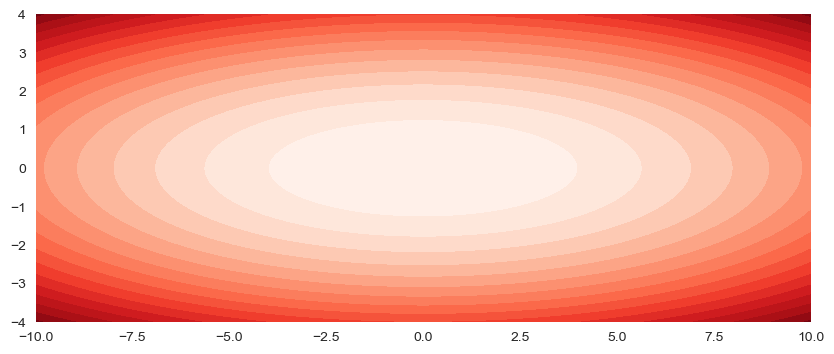

In [7]:
def fun1(X,Y):
    return 0.5*(X**2+10*Y**2)

def grad1(x):
    return np.array((x[0],10*x[1]))

ax=plot_descent(-10,10,-4,4,fun1,None)

Let's do gradient descent with learning rate $\eta=0.18$, which will turn out to be a good learning rate.

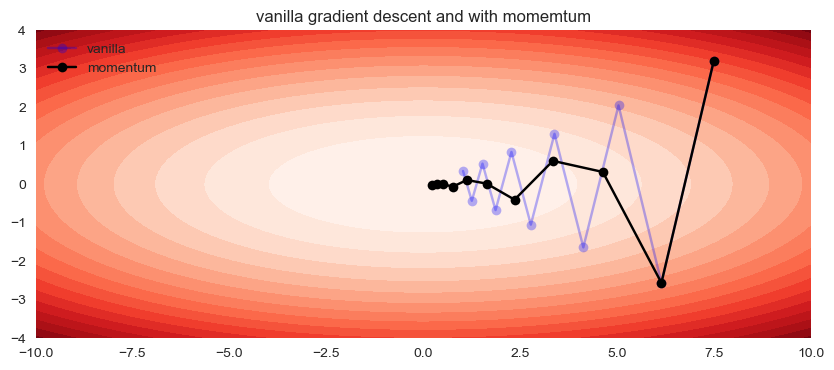

In [149]:
x0=np.array((7.5,3.2))

gamma=0.3
eta=0.18

path=gradient_descent(grad1,x0,eta)
path_mom=gd_momentum(grad1,x0,eta,gamma)
ax=plot_descent(-10,10,-4,4,fun1,path,alpha=0.3,label="vanilla")
ax.plot(path_mom[:,0],path_mom[:,1],"ko-",label="momentum")
ax.set_title("vanilla gradient descent and with momemtum")
ax.legend()
pass

In [102]:
def stochgrad1(x):
    sigma=1
    return grad1(x)*np.array((1+random.gauss(0,sigma),1+random.gauss(0,sigma)))

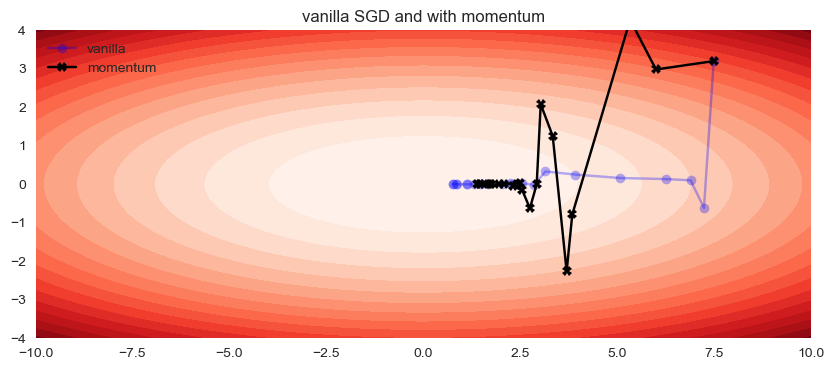

In [150]:
gamma=0.3
eta=0.075
STEPS=20

path=gradient_descent(stochgrad1,x0,eta,steps=STEPS)
path_mom=gd_momentum(stochgrad1,x0,eta,gamma,steps=STEPS)
ax=plot_descent(-10,10,-4,4,fun1,path,alpha=0.3,label="vanilla")
ax.plot(path_mom[:,0],path_mom[:,1],marker="X",color="k",label="momentum")
ax.set_title("vanilla SGD and with momentum")
ax.legend()

# Hyperparameter tuning

first, learning rate for SGD

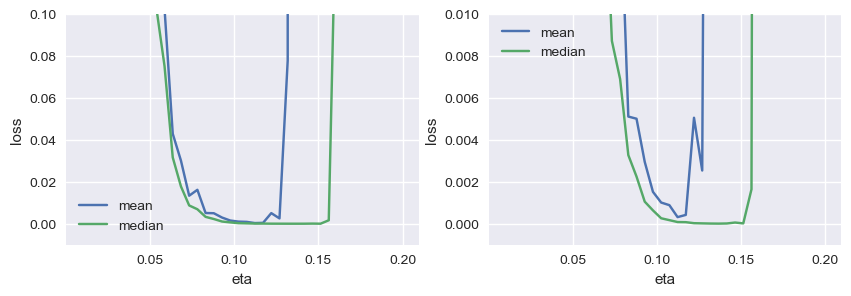

In [128]:
etas = np.linspace(0.01,0.2,40)
repeats=100
steps=50
result=[]
for eta in etas:
    losses=[]
    for _ in range(repeats):
        endpoint=gradient_descent(stochgrad1,x0,eta,steps=steps)[-1]
        losses.append(fun1(*endpoint))
    result.append((eta,np.mean(losses),np.median(losses)))
result=np.array(result)

fig,axs=plt.subplots(1,2,figsize=(10,3))
axs=iter(axs)
ax=next(axs)
ax.plot(result[:,0],result[:,1],label="mean")
ax.plot(result[:,0],result[:,-1],label="median")

ax.set_ylim(-0.01,0.1)
ax.set_xlabel("eta")
ax.set_ylabel("loss")
ax.legend()

ax=next(axs)
ax.plot(result[:,0],result[:,1],label="mean")
ax.plot(result[:,0],result[:,-1],label="median")

ax.set_ylim(-0.001,0.01)
ax.set_xlabel("eta")
ax.set_ylabel("loss")
ax.legend()
pass

$\eta=0.11$ seems fine

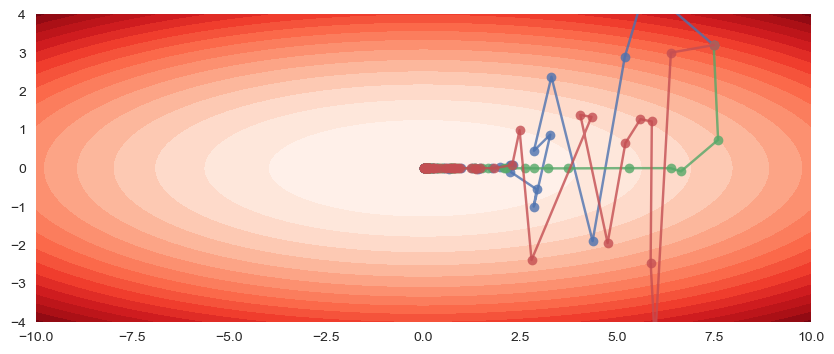

In [138]:
eta=0.11
start=0

repeats=3
endpoints=[]
ax=plot_descent(-10,10,-4,4,fun1,None,alpha=0.3)
for _ in range(repeats):
    path=gradient_descent(stochgrad1,x0,eta,steps=steps)
    endpoints.append(path[-1])
    ax.plot(path[start:,0],path[start:,1],"o-",alpha=0.8)

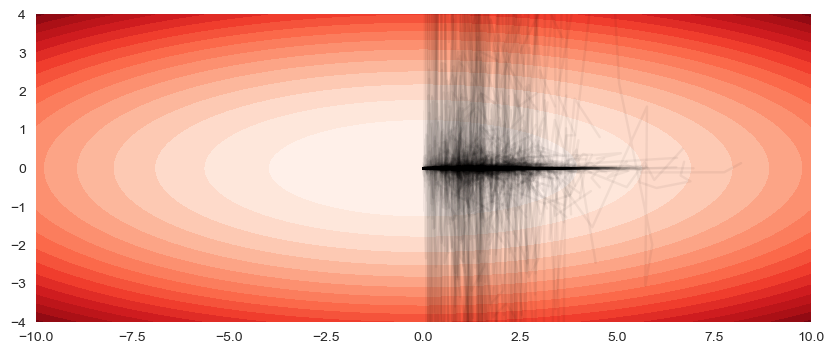

In [139]:
eta=0.11

start=10
steps=50

repeats=1000
endpoints=[]
ax=plot_descent(-10,10,-4,4,fun1,None,alpha=0.3)
for _ in range(repeats):
    path=gradient_descent(stochgrad1,x0,eta,steps=steps)
    endpoints.append(path[-1])
    ax.plot(path[start:,0],path[start:,1],"k-",alpha=0.05)

Text(0.5, 1.0, '22 of 1000 points outside plot')

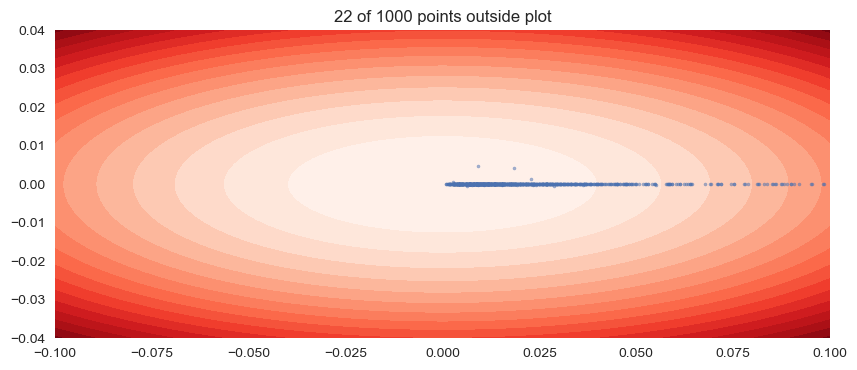

In [146]:
endpoints=np.array(endpoints)
window=[-0.1,0.1,-0.04,0.04]
is_inside=lambda x,y : x>=window[0] and x<=window[1] and y>=window[2] and y<=window[3]
num_outside=sum([not is_inside(*endpoint) for endpoint in endpoints])

ax=plot_descent(*window,fun1,None,alpha=0.3)
ax.scatter(endpoints[:,0],endpoints[:,1],alpha=0.5,s=5)
ax.set_title(f"{num_outside} of {len(endpoints)} points outside plot")

# Hyperparameters for momentum

In [79]:
etas = np.linspace(0.01,0.2,40)
gammas = np.linspace(0.1,0.6,20)
repeats=100
steps=50
result=[]
for gamma in gammas:
    for eta in etas:
        losses=[]
        for _ in range(repeats):
            endpoint=gd_momentum(stochgrad1,x0,eta,gamma,steps=steps)[-1]
            losses.append(fun1(*endpoint))
        result.append((eta,gamma,np.mean(losses),np.median(losses)))
result=np.array(result)

In [80]:
ind_array=np.argsort(result[:,-1])
result[ind_array][:10]

array([[9.28205128e-02, 4.15789474e-01, 3.31571599e-02, 3.67425092e-08],
       [8.79487179e-02, 4.15789474e-01, 1.82370747e-04, 3.95140614e-08],
       [9.76923077e-02, 3.89473684e-01, 1.98905588e+02, 4.49058106e-08],
       [1.17179487e-01, 3.10526316e-01, 9.98298166e+00, 5.06790235e-08],
       [1.02564103e-01, 3.36842105e-01, 1.19026301e-02, 5.88632494e-08],
       [8.30769231e-02, 4.42105263e-01, 2.22859899e-02, 6.98237217e-08],
       [1.07435897e-01, 3.10526316e-01, 3.13420309e-04, 7.49955509e-08],
       [9.76923077e-02, 3.63157895e-01, 5.84669507e-03, 7.77432455e-08],
       [8.79487179e-02, 4.42105263e-01, 1.95467078e-01, 8.78870389e-08],
       [9.76923077e-02, 3.36842105e-01, 2.49851005e-02, 9.86541070e-08]])

$\gamma=0.3,\, \eta=0.1$ seem fine.

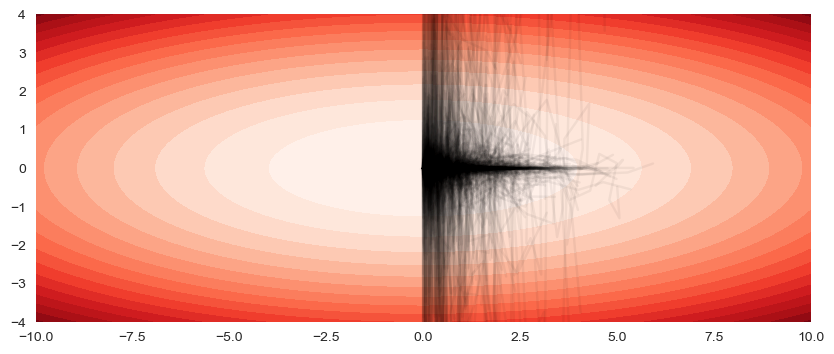

In [147]:
gamma=0.3
eta=0.1

endpoints=[]
repeats=1000
ax=plot_descent(-10,10,-4,4,fun1,None,alpha=0.3)
for _ in range(repeats):
    path_mom=gd_momentum(stochgrad1,x0,eta,gamma,steps=steps)
    endpoints.append(path_mom[-1])
    ax.plot(path_mom[start:,0],path_mom[start:,1],"k-",alpha=0.05)

Text(0.5, 1.0, '12 of 1000 points outside plot')

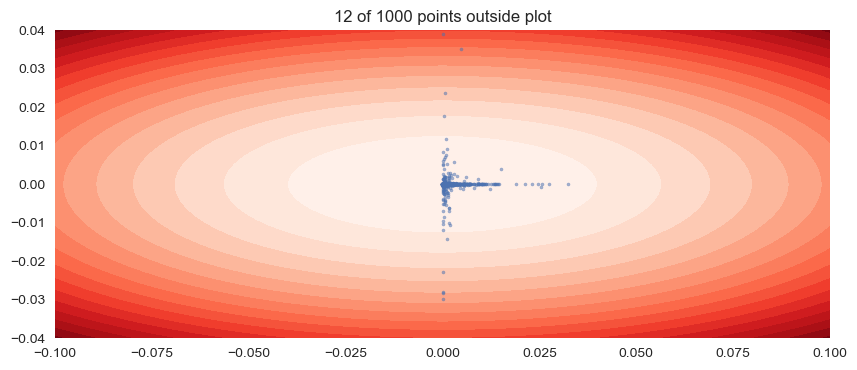

In [148]:
endpoints=np.array(endpoints)
window=[-0.1,0.1,-0.04,0.04]
is_inside=lambda x,y : x>=window[0] and x<=window[1] and y>=window[2] and y<=window[3]
num_outside=sum([not is_inside(*endpoint) for endpoint in endpoints])

ax=plot_descent(*window,fun1,None,alpha=0.3)
ax.scatter(endpoints[:,0],endpoints[:,1],alpha=0.5,s=5)
ax.set_title(f"{num_outside} of {len(endpoints)} points outside plot")